In [1]:
words = open('names.txt', 'r').read().splitlines()

In [2]:
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [3]:
len(words)

32033

In [4]:
min(len(w) for w in words)

2

In [5]:
max(len(w) for w in words)

15

In [12]:
b = {}
for w in words:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram = (ch1, ch2)
        b[bigram] = b.get(bigram, 0) + 1

In [17]:
sorted(b.items(), key = lambda kv: -kv[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [18]:
import torch

In [39]:
N = torch.zeros((27,27), dtype=torch.int32)

In [40]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [43]:
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1

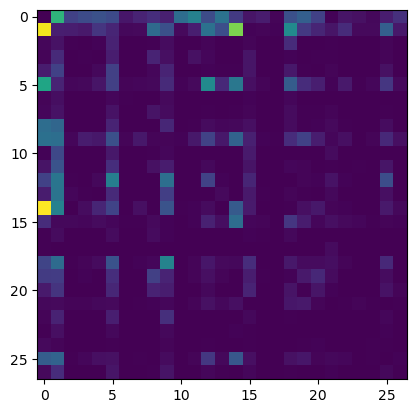

In [44]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.imshow(N)

In [68]:
N[0]

tensor([   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
        1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
         134,  535,  929], dtype=torch.int32)

In [69]:
p = N[0].float()
p = p / p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [70]:
g = torch.Generator().manual_seed(2147483647)
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
itos[ix]

'c'

In [58]:
g = torch.Generator().manual_seed(2147483647)
p = torch.rand(3, generator=g)
p = p / p.sum()
p

tensor([0.6064, 0.3033, 0.0903])

In [59]:
torch.multinomial(p, num_samples=20, replacement=True, generator=g)

tensor([1, 1, 2, 0, 0, 2, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1])

In [140]:
P = (N+1).float()
P /= P.sum(1, keepdim=True)

In [141]:
g = torch.Generator().manual_seed(2147483647)

for i in range(10):
    out = []
    ix = 0
    while True:
        p = P[ix]
        # p = N[ix].float()
        # p = p / p.sum()
        # p = torch.ones(27) / 27.0
        
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break
    print(''.join(out))

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.
da.
staiyaubrtthrigotai.
moliellavo.
ke.
teda.


In [151]:
log_likelihood = 0.0
n = 0

for w in words:
# for w in ["valq"]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        prob = P[ix1, ix2]
        logprob = torch.log(prob)
        log_likelihood += logprob
        n += 1
        # print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}')

print(f'{log_likelihood=}')
nll = -log_likelihood
print(f'{nll=}')
print(f'{nll/n}')

log_likelihood=tensor(-559951.5625)
nll=tensor(559951.5625)
2.4543561935424805


In [152]:
# create the training set of all bigrams (x,y)
xs, ys = [], []

for w in words[:1]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        xs.append(ix1)
        ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)
        

In [153]:
xs

tensor([ 0,  5, 13, 13,  1])

In [154]:
ys

tensor([ 5, 13, 13,  1,  0])

In [160]:
import torch.nn.functional as F
xenc = F.one_hot(xs, num_classes=27).float()
xenc

tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [161]:
xenc.shape

torch.Size([5, 27])

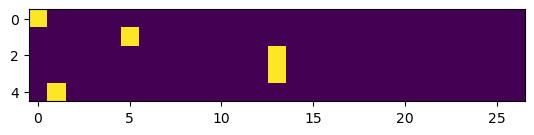

In [162]:
plt.imshow(xenc)

In [163]:
xenc.dtype

torch.float32

In [167]:
W = torch.randn((27, 27))
xenc @ W

tensor([[ 0.7683,  1.6930,  0.3829, -0.1097,  1.9684,  0.9273,  0.3533, -0.1890,
          0.0291,  1.1499,  0.5544,  0.3158,  2.1865,  0.1657,  0.3815,  0.8358,
         -0.2616, -0.4505, -0.3360, -0.3443,  1.8062,  0.5189,  0.5780, -2.1773,
         -1.8702,  0.6073, -0.3496],
        [-0.6817,  1.0968, -0.3457,  0.3992, -0.3898,  0.3200, -0.1465, -0.0826,
         -1.1014,  0.4192, -1.3575,  0.4674, -1.0394, -0.6575, -1.0872, -0.7610,
          0.2376,  1.4601, -0.0850,  0.7787, -0.4420,  1.9882,  0.0173, -0.1216,
          1.0418, -0.2198,  1.2687],
        [-0.3637,  0.8397, -0.6615, -0.5935,  0.6670, -0.3708,  1.1271, -0.3609,
         -0.1466,  0.2262,  0.0816, -1.4641, -1.2400, -1.2373,  0.8180,  0.1859,
          0.7750,  0.5038,  0.9500, -1.3874,  0.7998,  0.4030, -2.1617,  1.4421,
         -0.2045, -0.1459,  1.5000],
        [-0.3637,  0.8397, -0.6615, -0.5935,  0.6670, -0.3708,  1.1271, -0.3609,
         -0.1466,  0.2262,  0.0816, -1.4641, -1.2400, -1.2373,  0.8180,  0.1859

In [169]:
logits = xenc @ W # log-counts
counts = logits.exp() # equivalent to N
probs = counts / counts.sum(1, keepdims=True)
probs

tensor([[0.0370, 0.0933, 0.0252, 0.0154, 0.1229, 0.0434, 0.0244, 0.0142, 0.0177,
         0.0542, 0.0299, 0.0235, 0.1529, 0.0203, 0.0251, 0.0396, 0.0132, 0.0109,
         0.0123, 0.0122, 0.1045, 0.0289, 0.0306, 0.0019, 0.0026, 0.0315, 0.0121],
        [0.0124, 0.0737, 0.0174, 0.0367, 0.0167, 0.0339, 0.0213, 0.0227, 0.0082,
         0.0374, 0.0063, 0.0393, 0.0087, 0.0128, 0.0083, 0.0115, 0.0312, 0.1060,
         0.0226, 0.0536, 0.0158, 0.1797, 0.0250, 0.0218, 0.0698, 0.0198, 0.0875],
        [0.0179, 0.0596, 0.0133, 0.0142, 0.0501, 0.0178, 0.0794, 0.0179, 0.0222,
         0.0323, 0.0279, 0.0059, 0.0074, 0.0075, 0.0583, 0.0310, 0.0558, 0.0426,
         0.0665, 0.0064, 0.0572, 0.0385, 0.0030, 0.1088, 0.0210, 0.0222, 0.1153],
        [0.0179, 0.0596, 0.0133, 0.0142, 0.0501, 0.0178, 0.0794, 0.0179, 0.0222,
         0.0323, 0.0279, 0.0059, 0.0074, 0.0075, 0.0583, 0.0310, 0.0558, 0.0426,
         0.0665, 0.0064, 0.0572, 0.0385, 0.0030, 0.1088, 0.0210, 0.0222, 0.1153],
        [0.0120, 0.0099,

In [170]:
# OPTIMIZATION!!!

In [171]:
xs

tensor([ 0,  5, 13, 13,  1])

In [172]:
ys

tensor([ 5, 13, 13,  1,  0])

In [178]:
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

In [200]:
# forward pass
xenc = F.one_hot(xs, num_classes=27).float()
logits = xenc @ W
counts = logits.exp()
probs = counts / counts.sum(1, keepdims=True)
loss = -probs[torch.arange(5), ys].log().mean()

In [201]:
print(loss.item())

3.66926646232605


In [198]:
# backward pass
W.grad = None # set grad to zero
loss.backward()

In [199]:
# update
W.data += -0.1 * W.grad

In [210]:
xs, ys = [], []
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        xs.append(ix1)
        ys.append(ix2)
xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()
print('number of examples: ', num)

# initializa the 'network'
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

number of examples:  228146


In [211]:
# gradient descent
for k in range(100):
    # forward pass
    xenc = F.one_hot(xs, num_classes=27).float()
    logits = xenc @ W
    counts = logits.exp()
    probs = counts / counts.sum(1, keepdims=True)
    loss = -probs[torch.arange(num), ys].log().mean()
    print(loss.item())

    # backward pass
    W.grad = None # set grad to zero
    loss.backward()

    # update
    W.data += -50 * W.grad

3.758953094482422
3.371100664138794
3.154043197631836
3.020373821258545
2.927711248397827
2.8604023456573486
2.8097290992736816
2.7701022624969482
2.7380731105804443
2.711496353149414
2.6890032291412354
2.6696884632110596
2.6529300212860107
2.638277292251587
2.6253879070281982
2.613990545272827
2.60386323928833
2.5948216915130615
2.5867116451263428
2.5794036388397217
2.572789192199707
2.5667762756347656
2.5612881183624268
2.5562589168548584
2.551633596420288
2.547366142272949
2.543415069580078
2.5397486686706543
2.5363364219665527
2.533154249191284
2.5301806926727295
2.5273969173431396
2.5247862339019775
2.522334575653076
2.520029067993164
2.517857789993286
2.515810489654541
2.513878345489502
2.512052059173584
2.510324001312256
2.5086867809295654
2.5071346759796143
2.5056614875793457
2.504261016845703
2.5029289722442627
2.5016613006591797
2.5004520416259766
2.4992988109588623
2.498197317123413
2.497144937515259
2.496137857437134
2.495173692703247
2.4942493438720703
2.493363380432129
2.